# 01 · Aquisição de imagens de fundo de olho

**Ementa 01** · continuação da *Aula 1 — Aquisição de Imagens de Fundo de Olho* (documento de transição Módulo 1 → 2)

O Módulo 1 terminou onde a luz refletida pelo fundo de olho atinge o sensor. Aqui a retinografia deixa de ser um fenômeno
óptico e passa a ser uma **estrutura de dados**. Neste notebook você vai:

1. simular **do fóton ao pixel**: amostragem (resolução) e quantização (profundidade de bits);
2. abrir a imagem como **matriz** `H × W × 3` e ler pixels;
3. medir como **resolução** e **compressão JPEG** afetam o que o processamento posterior consegue recuperar;
4. traduzir os **quatro critérios de qualidade do Módulo 1** (foco, iluminação, centralização, artefatos) em números;
5. preparar o **protocolo de captura** da sessão presencial no Laboratório Maker (retinógrafo com Raspberry Pi Camera Module 3).

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from retina_pdi import dados, pipeline as P, visualizacao as V

V.configurar_estilo()
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__} | pandas {pd.__version__}")
from skimage.metrics import structural_similarity as ssim
from retina_pdi import degradacoes, qualidade as Q

OpenCV 4.14.0 | NumPy 2.5.3 | pandas 3.0.6


## 1. Do fóton ao pixel: amostragem e quantização

Cada fotossítio do sensor acumula carga proporcional à luz recebida (**integra** a luz sobre a sua área) e o conversor A/D
transforma essa carga em um inteiro. Dois "discretizadores" acontecem, portanto:

* **amostragem espacial** — quantos fotossítios cobrem a cena (resolução);
* **quantização** — em quantos níveis cada medida é arredondada (profundidade de bits).

Vamos simular um sensor com **menos fotossítios** reduzindo a imagem por média de área (`INTER_AREA` faz exatamente a integração de luz
sobre uma área maior). Usamos uma imagem HRF de retinopatia diabética em resolução total (3504×2336).

hrf_08_dr: 3504×2336 px, dtype=uint8, 24.6 MB na memória


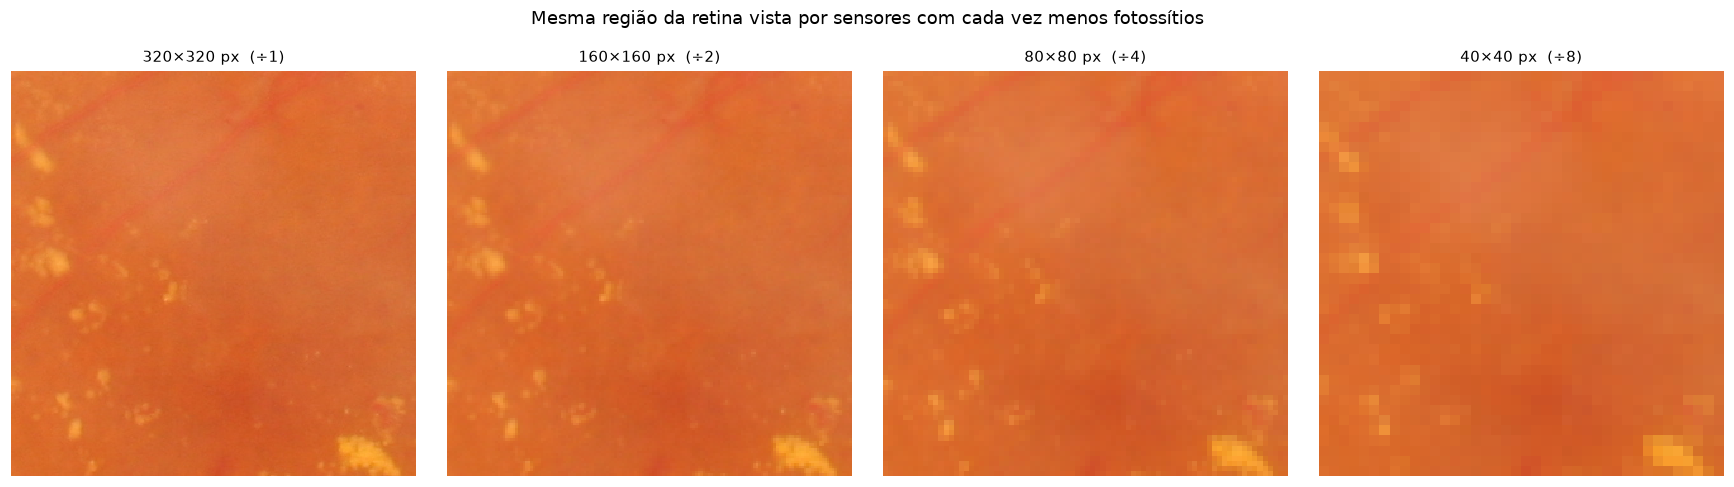

In [2]:
reg = dados.carregar_registro(dados.selecionar("rd", "hrf").query("id == 'hrf_08_dr'").iloc[0])
rgb = reg["rgb"]
h, w = rgb.shape[:2]
print(f"{reg['meta'].id}: {w}×{h} px, dtype={rgb.dtype}, {rgb.nbytes/1e6:.1f} MB na memória")

# recorte 320×320 perto do centro (região macular), em resolução nativa
L = 320
y0, x0 = h // 2 - L // 2, w // 2 - L // 2
recorte = rgb[y0:y0 + L, x0:x0 + L]

fatores = [1, 2, 4, 8]
fig, axs = plt.subplots(1, len(fatores), figsize=(4 * len(fatores), 4.3))
for ax, f in zip(axs, fatores):
    lado = L // f
    sensor = cv2.resize(recorte, (lado, lado), interpolation=cv2.INTER_AREA)   # menos fotossítios
    ax.imshow(cv2.resize(sensor, (L, L), interpolation=cv2.INTER_NEAREST))      # só para exibir do mesmo tamanho
    ax.set_title(f"{lado}×{lado} px  (÷{f})"); ax.axis("off")
fig.suptitle("Mesma região da retina vista por sensores com cada vez menos fotossítios", y=1.02)
fig.tight_layout(); V.salvar_figura(fig, "01_amostragem_resolucao"); plt.show()

Repare: com ÷4 ou ÷8 os **pequenos exsudatos amarelos** e o vaso fino viram manchas de poucos pixels — e abaixo disso deixam de existir.
Nenhum algoritmo, por mais sofisticado, recupera o que o sensor não amostrou. É por isso que a escolha do sensor (Módulo 3) define o limite superior de detalhe de tudo o que vem depois.

## 2. Anatomia de uma imagem digital

Uma imagem colorida é uma matriz 3D: **altura × largura × canais**. Em 8 bits por canal cada valor vai de 0 a 255 (256 níveis).
Abaixo, um recorte de **5×5 pixels** ampliado até o nível de um único pixel — a mesma ideia da Figura 2 da Aula 1.

shape        : (2336, 3504, 3) → (altura, largura, canais)
dtype        : uint8 → 8 bits por canal, valores de 0 a 255
níveis/canal : 256
pixel [0,0]  : [0 1 0] (moldura preta, fora do campo de visão)
pixel central: R=229  G=131  B=34   (posição y=1305, x=1851)


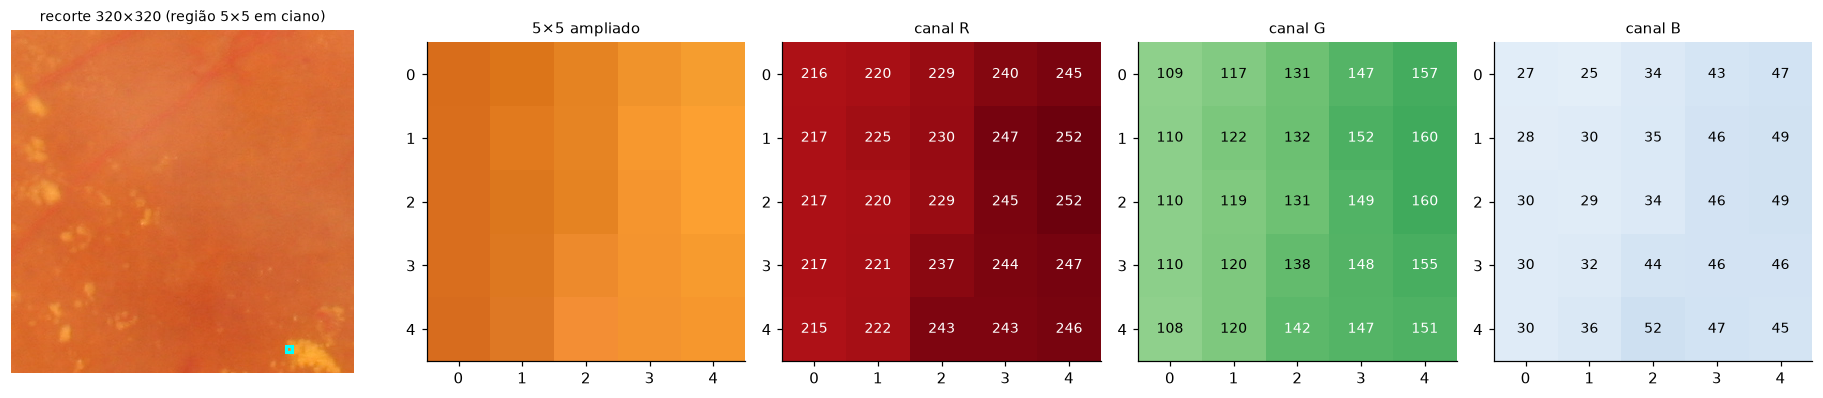

In [3]:
print("shape        :", rgb.shape, "→ (altura, largura, canais)")
print("dtype        :", rgb.dtype, "→ 8 bits por canal, valores de", rgb.min(), "a", rgb.max())
print("níveis/canal :", 2 ** (rgb.itemsize * 8))
print("pixel [0,0]  :", rgb[0, 0], "(moldura preta, fora do campo de visão)")

# para o exemplo ficar interessante, escolhemos o patch 5×5 de MAIOR contraste local do recorte (a borda de um exsudato)
g = recorte[..., 1].astype(np.float32)
desvio_local = np.sqrt(np.maximum(cv2.blur(g * g, (5, 5)) - cv2.blur(g, (5, 5)) ** 2, 0))
desvio_local[:10], desvio_local[-10:], desvio_local[:, :10], desvio_local[:, -10:] = 0, 0, 0, 0   # ignora a margem do recorte
yy, xx = np.unravel_index(np.argmax(desvio_local), desvio_local.shape)
py, px = y0 + yy - 2, x0 + xx - 2           # canto superior esquerdo do patch 5×5
patch = rgb[py:py + 5, px:px + 5]           # 5×5×3
pixel = patch[2, 2]
print(f"pixel central: R={pixel[0]}  G={pixel[1]}  B={pixel[2]}   (posição y={py + 2}, x={px + 2})")

fig, axs = plt.subplots(1, 5, figsize=(17, 3.6), gridspec_kw={"width_ratios": [1.3, 1, 1, 1, 1]})
axs[0].imshow(recorte); axs[0].add_patch(plt.Rectangle((px - x0 - 0.5, py - y0 - 0.5), 5, 5, fill=False, ec="cyan", lw=2))
axs[0].set_title(f"recorte {L}×{L} (região 5×5 em ciano)", fontsize=9); axs[0].axis("off")
axs[1].imshow(patch, interpolation="nearest"); axs[1].set_title("5×5 ampliado"); axs[1].set_xticks(range(5)); axs[1].set_yticks(range(5))
for k, (nome, cmap) in enumerate([("R", "Reds"), ("G", "Greens"), ("B", "Blues")]):
    ax = axs[2 + k]; ax.imshow(patch[..., k], cmap=cmap, vmin=0, vmax=255)
    for (i, j), v in np.ndenumerate(patch[..., k]):
        ax.text(j, i, int(v), ha="center", va="center", fontsize=9, color="white" if v > 140 else "black")
    ax.set_title(f"canal {nome}"); ax.set_xticks(range(5)); ax.set_yticks(range(5))
fig.tight_layout(); V.salvar_figura(fig, "01_anatomia_pixel"); plt.show()

**Indexação** (memorize — é a base de todo o resto do módulo):

| Expressão | Significado |
|---|---|
| `img[y, x]` | os 3 números (R, G, B) do pixel na linha `y`, coluna `x` — **linha primeiro!** |
| `img[..., 1]` | o canal verde inteiro (matriz H×W) |
| `img[y0:y1, x0:x1]` | recorte (uma *view*, não uma cópia — use `.copy()` se for alterar) |
| `img.shape[:2]` | `(altura, largura)` — o oposto do que `cv2.resize` espera `(largura, altura)` |

## 3. Resolução: quantos pixels tem uma lesão?

Resolução em pixels só faz sentido comparada ao **tamanho físico** das estruturas. Usamos o **disco óptico** como régua:
seu diâmetro é ≈ 1,8 mm (valor aproximado da literatura; varia entre pessoas), e uma lesão pequena como um microaneurisma tem ≈ 20–100 µm.
Medimos o diâmetro do disco em pixels (função `localizar_disco_optico`, que veremos no notebook 04) em cada fonte:

In [4]:
linhas = []
for _, r in dados.carregar_manifesto().iterrows():
    img = dados.carregar_rgb(r.arquivo)
    pequena = dados.reduzir(img, 512); esc = img.shape[1] / pequena.shape[1]
    fov = P.mascara_fov(pequena); d = P.localizar_disco_optico(pequena, fov)
    if d.raio is None:
        continue
    y0_, y1_, x0_, x1_ = P.caixa_fov(fov)
    linhas.append(dict(fonte=r.fonte, largura=img.shape[1], altura=img.shape[0],
                       fov_px=max(y1_ - y0_, x1_ - x0_) * esc, disco_px=2 * d.raio * esc))
res = pd.DataFrame(linhas).groupby("fonte").median().round(0)
res["disco/FOV"] = (res.disco_px / res.fov_px).round(3)
res["µm/pixel*"] = (1800 / res.disco_px).round(1)
res["pixels p/ microaneurisma de 50 µm"] = (50 / res["µm/pixel*"]).round(1)
res

,largura,altura,fov_px,disco_px,disco/FOV,µm/pixel*,pixels p/ microaneurisma de 50 µm
fonte,,,,,,,
HRF,3504.0,2336.0,3278.0,320.0,0.098,5.6,8.9
ODIR,512.0,512.0,512.0,72.0,0.141,25.0,2.0
RFMiD,2048.0,1536.0,1480.0,211.0,0.143,8.5,5.9


In [5]:
# Cenário: o retinógrafo Retina em Foco (sensor IMX708, 4608×2592). Suposição: o círculo do campo de visão ocupa a altura do sensor.
razao = res["disco/FOV"].median()
fov_imx = 2592
disco_imx = razao * fov_imx
um_por_px = 1800 / disco_imx
print(f"razão disco/FOV mediana nas 3 fontes: {razao:.3f}")
print(f"IMX708 (FOV = {fov_imx} px): disco ≈ {disco_imx:.0f} px → ≈ {um_por_px:.1f} µm/pixel → microaneurisma de 50 µm ≈ {50/um_por_px:.1f} px")
print("* valores ilustrativos: assumem disco = 1,8 mm e a geometria ótica definitiva só será conhecida ao final do Módulo 3.")

razão disco/FOV mediana nas 3 fontes: 0.141
IMX708 (FOV = 2592 px): disco ≈ 365 px → ≈ 4.9 µm/pixel → microaneurisma de 50 µm ≈ 10.2 px
* valores ilustrativos: assumem disco = 1,8 mm e a geometria ótica definitiva só será conhecida ao final do Módulo 3.


A razão disco/FOV varia com a câmera e o enquadramento (o ODIR está recortado mais justo que o HRF), então tome os números como **ordem de grandeza**.
O HRF é a referência mais confiável (imagem original, campo de ≈ 45°).

Interpretação: mesmo uma imagem **grande** (12 MP) só deixa alguns pixels para um microaneurisma pequeno — e o modelo de IA receberá uma versão **reduzida para 224×224**
(notebook 06), onde ele ocupa menos de 1 pixel. Detalhes finos só sobrevivem se o pré-processamento for cuidadoso, e alguns só podem ser detectados em recortes de maior resolução.

## 4. Profundidade de bits: quantos níveis bastam?

O conversor A/D decide quantos níveis existem por canal. Vamos reduzir o canal verde de 8 bits (256 níveis) para menos bits e observar
o efeito (posterização) e o erro (PSNR, em dB — quanto maior, mais fiel).

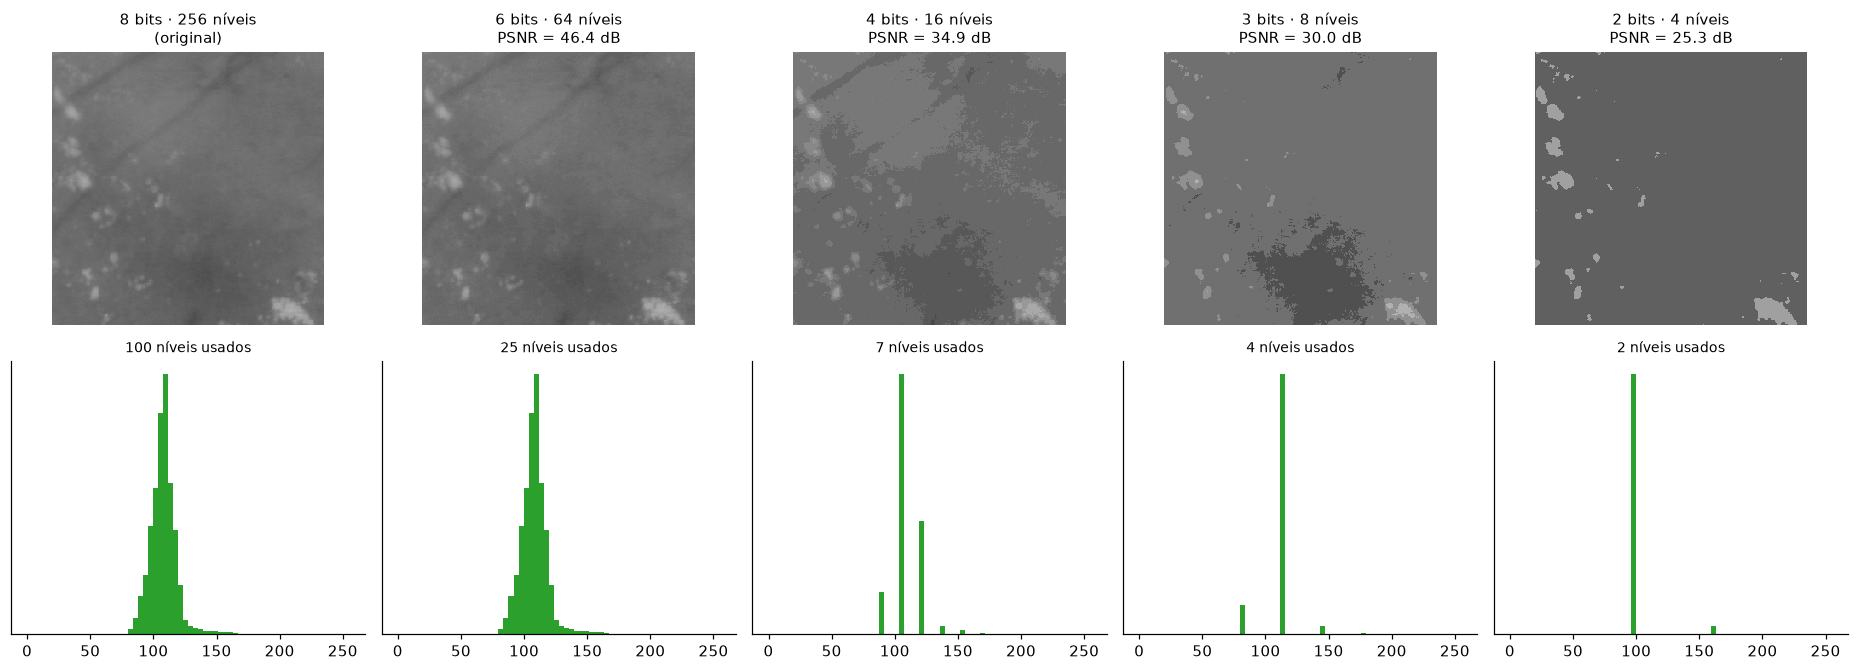

In [6]:
verde = recorte[..., 1]

def quantizar(canal, bits):
    passo = 2 ** (8 - bits)
    return ((canal // passo) * passo + passo // 2).clip(0, 255).astype(np.uint8)

bits = [8, 6, 4, 3, 2]
fig, axs = plt.subplots(2, len(bits), figsize=(3.4 * len(bits), 6.2))
for k, b in enumerate(bits):
    q = quantizar(verde, b) if b < 8 else verde
    axs[0, k].imshow(q, cmap="gray", vmin=0, vmax=255); axs[0, k].axis("off")
    axs[0, k].set_title(f"{b} bits · {2**b} níveis\nPSNR = {cv2.PSNR(verde, q):.1f} dB" if b < 8 else "8 bits · 256 níveis\n(original)")
    axs[1, k].hist(q.ravel(), bins=64, range=(0, 255), color="tab:green"); axs[1, k].set_yticks([])
    axs[1, k].set_title(f"{len(np.unique(q))} níveis usados", fontsize=9)
fig.tight_layout(); V.salvar_figura(fig, "01_quantizacao"); plt.show()

Com ≥ 6 bits é difícil ver diferença; com ≤ 4 aparecem *bandas* (falsos contornos) que confundem qualquer filtro de gradiente. Por isso 8 bits por canal é o padrão — e é o que o modelo TFLite quantizado (`uint8`) também espera na entrada.

## 5. Compressão JPEG: o que se perde ao salvar

JPEG descarta informação (principalmente detalhes finos e cor) para reduzir o tamanho. Compare qualidades de compressão numa imagem de 1024 px:
tamanho do arquivo, PSNR e SSIM (1 = idêntica) em relação à imagem de origem.

In [7]:
base = dados.reduzir(dados.carregar_rgb(dados.selecionar("normal", "rfmid").iloc[0].arquivo), 1024)
bgr = cv2.cvtColor(base, cv2.COLOR_RGB2BGR)
png = cv2.imencode(".png", bgr)[1].nbytes / 1e3

qualidades = [95, 75, 50, 25, 10]
linhas, imagens = [], []
for q in qualidades:
    dado = cv2.imencode(".jpg", bgr, [cv2.IMWRITE_JPEG_QUALITY, q])[1]
    dec = cv2.cvtColor(cv2.imdecode(dado, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    imagens.append(dec)
    linhas.append(dict(qualidade=q, KB=dado.nbytes / 1e3, PSNR_dB=cv2.PSNR(base, dec), SSIM=ssim(base, dec, channel_axis=2)))
print(f"PNG sem perdas: {png:.0f} KB   |   matriz crua (uint8): {base.nbytes/1e3:.0f} KB")
pd.DataFrame(linhas).round(3)

PNG sem perdas: 765 KB   |   matriz crua (uint8): 2359 KB


,qualidade,KB,PSNR_dB,SSIM
0,95,149.209,42.462,0.964
1,75,48.490,38.856,0.923
2,50,30.169,37.051,0.796
3,25,19.949,35.675,0.750
4,10,15.083,32.769,0.697


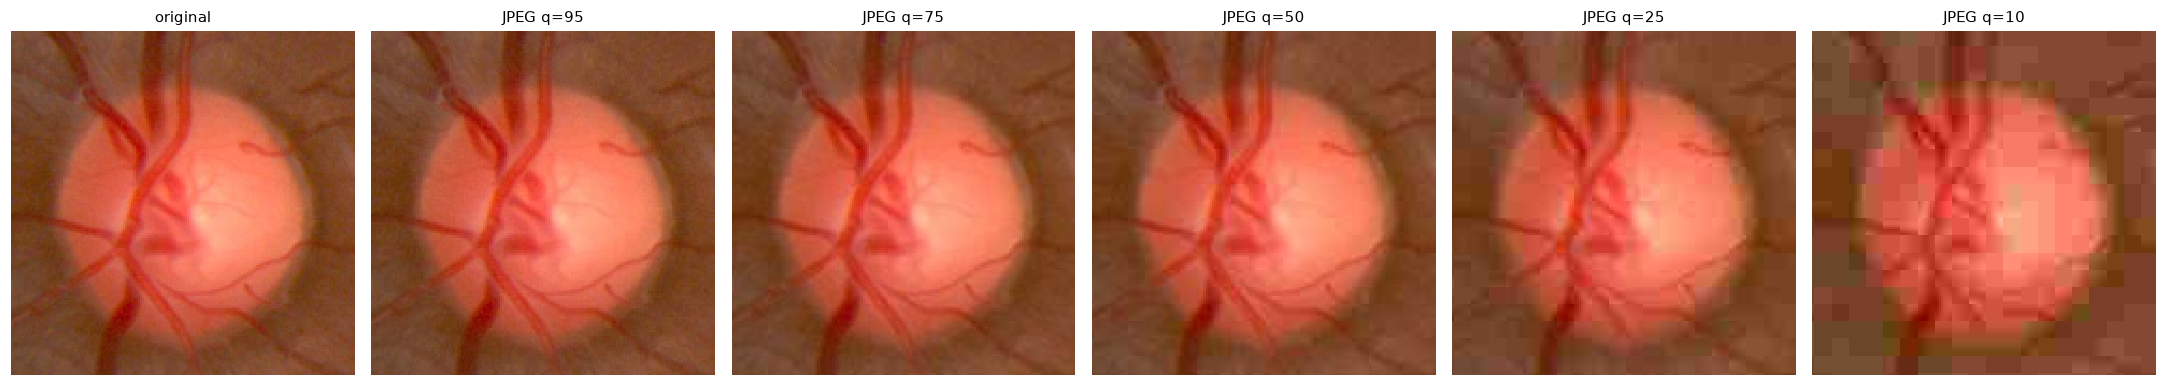

In [8]:
# zoom numa região de vasos finos (ao redor do disco óptico)
d0 = P.localizar_disco_optico(base)
cy, cx = (int(v) for v in d0.centro)
ys, xs = slice(max(cy - 80, 0), cy + 80), slice(max(cx - 80, 0), cx + 80)
fig, axs = plt.subplots(1, len(qualidades) + 1, figsize=(3.3 * (len(qualidades) + 1), 3.6))
for ax, (titulo, im) in zip(axs, [("original", base)] + [(f"JPEG q={q}", im) for q, im in zip(qualidades, imagens)]):
    ax.imshow(im[ys, xs]); ax.set_title(titulo); ax.axis("off")
fig.tight_layout(); V.salvar_figura(fig, "01_jpeg_zoom"); plt.show()

> **Regra prática para o protótipo:** guarde as capturas em **PNG** (ou JPEG com qualidade ≥ 95) e só comprima para transmissão/arquivo.
> Repare que as bases públicas já vêm em JPEG — recomprimi-las acumula perdas.

## 6. Do critério visual à métrica (Módulo 1 → Módulo 2)

A Aula 5 do Módulo 1 apresentou quatro critérios de qualidade. Cada um corresponde a uma **propriedade mensurável na matriz**
(Figura 3 da Aula 1). Vamos ver os quatro em ação, usando as degradações sintéticas de `retina_pdi.degradacoes`
(assim conhecemos exatamente o defeito aplicado).

| Critério (Módulo 1) | Propriedade na matriz (Módulo 2) | Métrica |
|---|---|---|
| Foco | variação de alta frequência entre pixels vizinhos | variância do Laplaciano |
| Iluminação | formato do histograma de intensidades | média, saturação, uniformidade |
| Centralização | posição das estruturas na matriz | coordenadas do FOV / do disco |
| Artefatos | regiões anomalamente uniformes ou escuras | fração de pixels escuros |

In [9]:
orig_grande = dados.carregar_rgb(dados.selecionar("normal", "hrf").iloc[0].arquivo)
ref = dados.reduzir(orig_grande, 1024)
fov_ref = P.mascara_fov(ref)

### 6.1 Foco → variância do Laplaciano

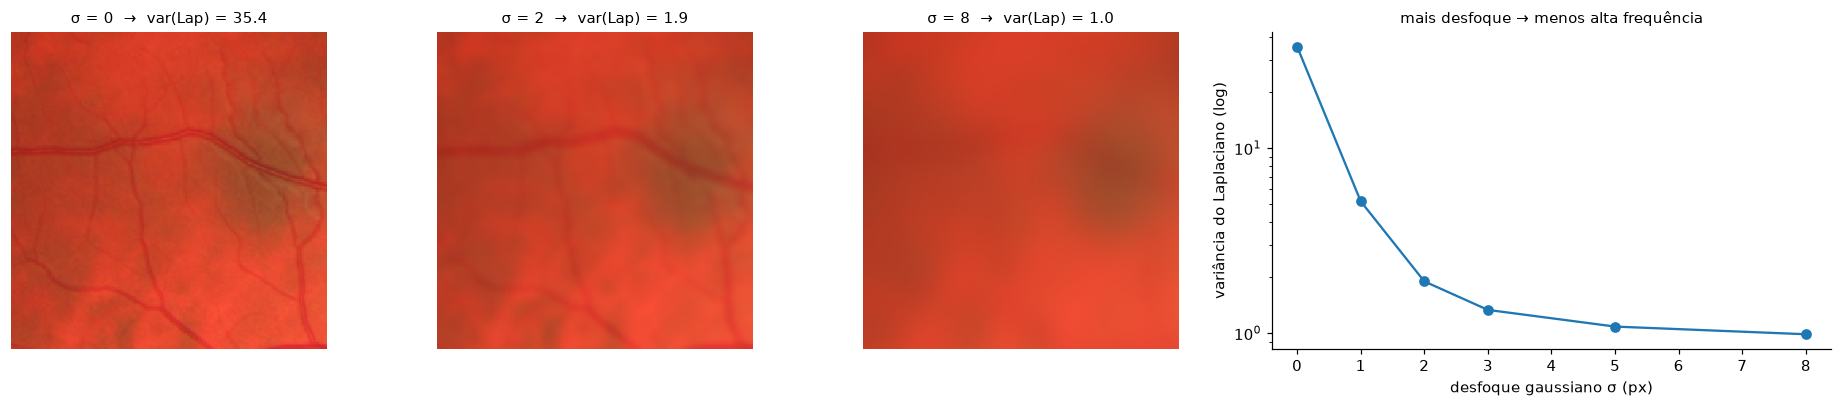

In [10]:
def var_laplaciano(rgb):
    """Métrica clássica: variância do Laplaciano do canal verde (mais borda/detalhe → maior)."""
    return cv2.Laplacian(rgb[..., 1], cv2.CV_64F).var()

sigmas = [0, 1, 2, 3, 5, 8]
vals, exemplos = [], []
for s in sigmas:
    im = ref if s == 0 else cv2.GaussianBlur(ref, (0, 0), s)
    vals.append(var_laplaciano(im)); exemplos.append(im)

fig, axs = plt.subplots(1, 4, figsize=(17, 3.8), gridspec_kw={"width_ratios": [1, 1, 1, 1.6]})
for ax, k in zip(axs[:3], [0, 2, 5]):
    ax.imshow(exemplos[k][350:550, 300:500]); ax.axis("off"); ax.set_title(f"σ = {sigmas[k]}  →  var(Lap) = {vals[k]:.1f}")
axs[3].semilogy(sigmas, vals, "o-"); axs[3].set_xlabel("desfoque gaussiano σ (px)"); axs[3].set_ylabel("variância do Laplaciano (log)")
axs[3].set_title("mais desfoque → menos alta frequência")
fig.tight_layout(); V.salvar_figura(fig, "01_foco_laplaciano"); plt.show()

**Cuidado — a métrica depende da resolução.** A mesma cena, mostrada com menos pixels, tem "bordas mais abruptas por pixel".
Compare a variância do Laplaciano da *mesma* imagem, sem nenhum defeito, em quatro tamanhos:

In [11]:
larguras = [2048, 1024, 512, 256]
tab = pd.DataFrame({"largura (px)": larguras,
                    "var(Laplaciano)": [var_laplaciano(dados.reduzir(orig_grande, L)) for L in larguras]})
tab["relativo a 512 px"] = (tab["var(Laplaciano)"] / tab.loc[tab["largura (px)"] == 512, "var(Laplaciano)"].iloc[0]).round(2)
tab.round(2)

,largura (px),var(Laplaciano),relativo a 512 px
0,2048,11.81,0.12
1,1024,35.41,0.37
2,512,96.79,1.00
3,256,202.26,2.09


Sem defeito algum, o valor varia várias vezes só por mudar a resolução — comparar imagens de câmeras diferentes com essa métrica *crua* engana. Por isso o módulo `qualidade` **padroniza** a imagem (recorte do FOV, 512×512) antes de medir (notebook 05).

### 6.2 Iluminação → histograma

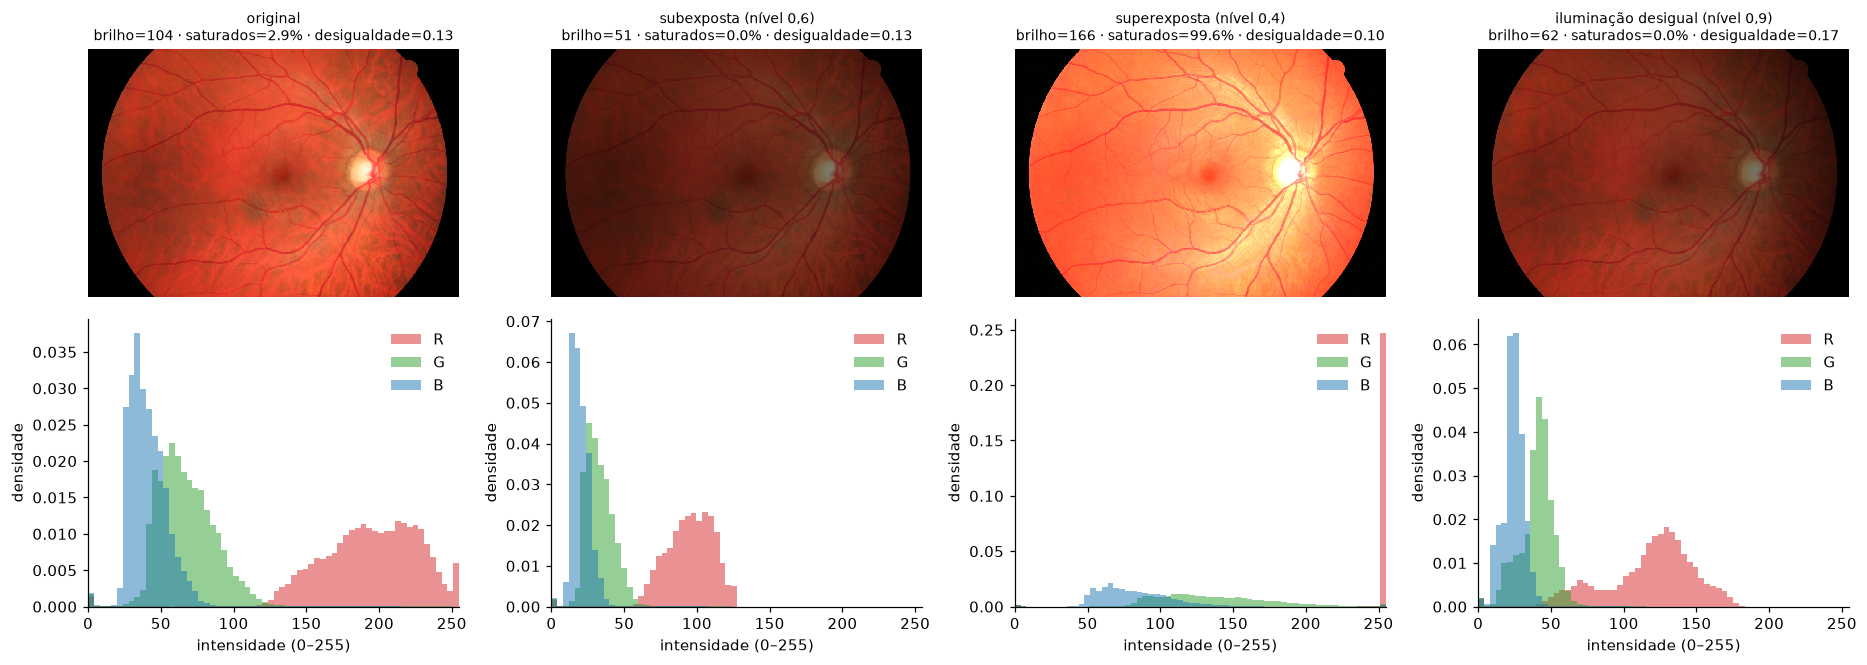

In [12]:
casos = [("original", ref),
         ("subexposta (nível 0,6)", degradacoes.aplicar(ref, "escuro", 0.6)),
         ("superexposta (nível 0,4)", degradacoes.aplicar(ref, "claro", 0.4)),
         ("iluminação desigual (nível 0,9)", degradacoes.aplicar(ref, "desigual", 0.9, seed=4))]
fig, axs = plt.subplots(2, 4, figsize=(17, 6.2))
for k, (nome, im) in enumerate(casos):
    m_ = Q.metricas_qualidade(im)
    axs[0, k].imshow(im); axs[0, k].axis("off")
    axs[0, k].set_title(f"{nome}\nbrilho={m_['brilho']:.0f} · saturados={100*m_['p_saturado']:.1f}% · desigualdade={m_['desigualdade']:.2f}", fontsize=9)
    V.histogramas_rgb(im, fov_ref, ax=axs[1, k])
    axs[1, k].set_xlim(0, 255)
fig.tight_layout(); V.salvar_figura(fig, "01_iluminacao_histograma"); plt.show()

* **subexposta** → histograma empurrado para a esquerda (pouca faixa dinâmica usada); **superexposta** → pico em 255 (informação perdida por saturação, irrecuperável); **desigual** → histograma largo e achatado e *gradiente espacial* de brilho.

### 6.3 Centralização → coordenadas na matriz

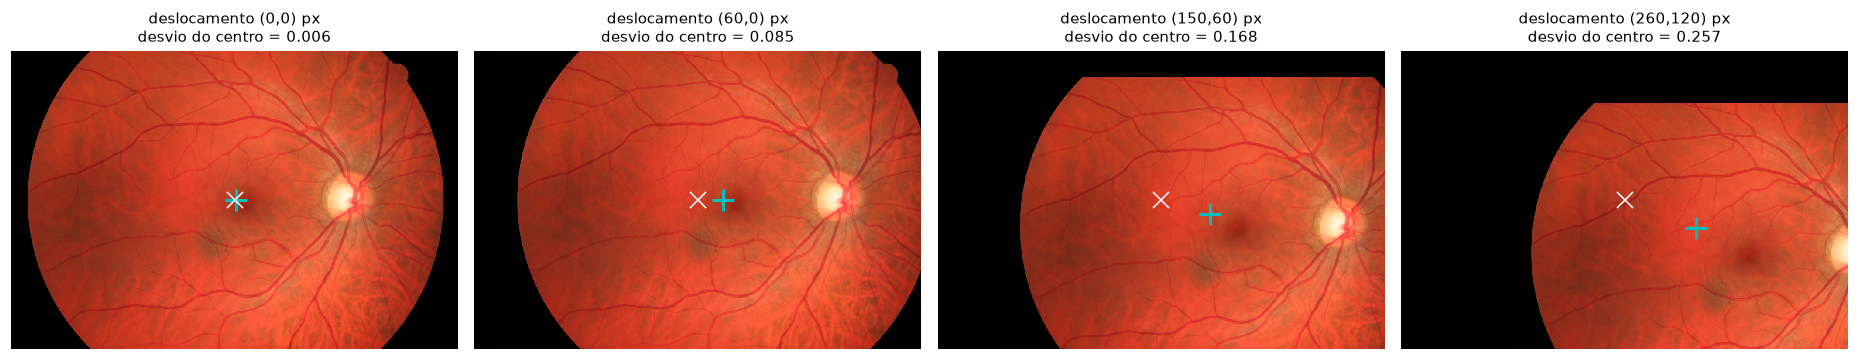

disco óptico em (y, x) = (334, 764) px → 0.49 da altura, 0.75 da largura


In [13]:
def deslocar(rgb, dx, dy):
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(rgb, M, (rgb.shape[1], rgb.shape[0]))   # o que sai do quadro é perdido; o resto fica preto

fig, axs = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, (dx, dy) in zip(axs, [(0, 0), (60, 0), (150, 60), (260, 120)]):
    im = deslocar(ref, dx, dy); f = P.mascara_fov(im); ys_, xs_ = np.where(f)
    desvio = np.hypot(xs_.mean() - im.shape[1] / 2, ys_.mean() - im.shape[0] / 2) / min(im.shape[:2])
    ax.imshow(im); ax.plot(xs_.mean(), ys_.mean(), "c+", ms=14, mew=2); ax.plot(im.shape[1] / 2, im.shape[0] / 2, "wx", ms=10)
    ax.set_title(f"deslocamento ({dx},{dy}) px\ndesvio do centro = {desvio:.3f}"); ax.axis("off")
fig.tight_layout(); plt.show()

# posição do disco óptico: coordenadas (linha, coluna) normalizadas pelo tamanho da imagem
d = P.localizar_disco_optico(ref, fov_ref)
print(f"disco óptico em (y, x) = ({d.centro[0]:.0f}, {d.centro[1]:.0f}) px → {d.centro[0]/ref.shape[0]:.2f} da altura, {d.centro[1]/ref.shape[1]:.2f} da largura")

### 6.4 Artefatos → regiões anormalmente escuras

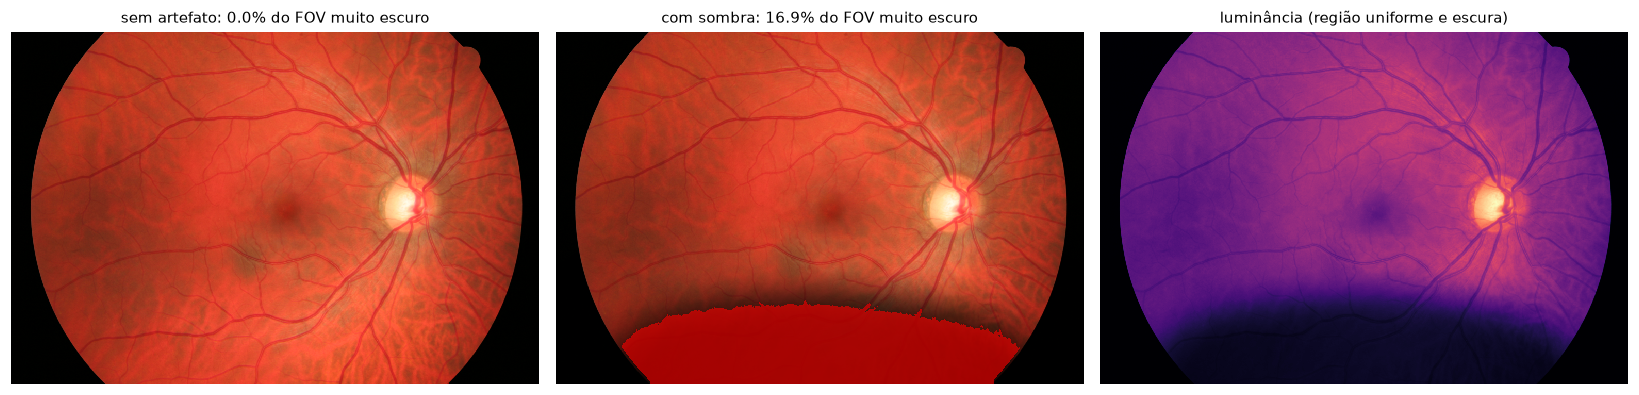

In [14]:
# simula a sombra de uma pálpebra/cílios: elipse escura suavizada sobre a borda inferior do campo de visão
art = ref.copy().astype(np.float32)
sombra = np.zeros(ref.shape[:2], np.float32)
cv2.ellipse(sombra, (ref.shape[1] // 2, ref.shape[0] - 40), (420, 150), 0, 0, 360, 1.0, -1)
sombra = cv2.GaussianBlur(sombra, (0, 0), 35)
art = (art * (1 - 0.85 * sombra[..., None])).clip(0, 255).astype(np.uint8)

def regiao_escura(rgb, fov, limiar=35):
    interior = P.erodir_fov(fov, 8)
    escuro = (cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY) < limiar) & interior
    return escuro.sum() / interior.sum(), escuro

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nome, im) in zip(axs[:2], [("sem artefato", ref), ("com sombra", art)]):
    fr, mascara = regiao_escura(im, fov_ref)
    ax.imshow(V.sobrepor(im, mascara, (255, 0, 0), 0.6)); ax.set_title(f"{nome}: {100*fr:.1f}% do FOV muito escuro"); ax.axis("off")
axs[2].imshow(cv2.cvtColor(art, cv2.COLOR_RGB2GRAY), cmap="magma"); axs[2].set_title("luminância (região uniforme e escura)"); axs[2].axis("off")
fig.tight_layout(); plt.show()

## 7. Sessão presencial no Laboratório Maker (4 h)

Na prática com o retinógrafo você vai capturar imagens reais e **avaliar foco, iluminação e enquadramento** — os três critérios acima.
Use o roteiro abaixo; ao final, o notebook 05 mede a fração de capturas adequadas (**meta do edital: ≥ 80 %**).

**Roteiro de captura**
1. Monte o dispositivo, acenda o LED (PWM baixo → alto) e verifique a uniformidade do campo sobre um **alvo de teste** (folha branca/cinza; depois um olho-modelo, se disponível).
2. Ajuste o **foco** com a lente de +20 D e a posição da lente da câmera; capture uma sequência variando só o foco.
3. Varie **um parâmetro por vez** (LED, tempo de exposição, ganho); anote tudo no registro de captura.
4. Salve em **PNG**, nome padronizado `AAAAMMDD_sessao_NNN.png`.
5. Repita ≥ 20 capturas "boas" (para calibrar limiares no próprio dispositivo) e ≥ 10 com defeitos deliberados (foco, luz).

O modelo de registro abaixo já sai do notebook em CSV:

In [15]:
registro = pd.DataFrame({
    "arquivo": ["20260921_lab_001.png", "20260921_lab_002.png"],
    "alvo": ["folha branca", "olho-modelo"],
    "led_pwm_%": [30, 60], "exposicao_us": [8000, 8000], "ganho_analogico": [1.0, 1.0],
    "posicao_lente": [4.0, 4.5], "operador": ["", ""], "observacao_visual": ["sombra no canto inferior", "bom foco"],
    "adequada_visual(s/n)": ["n", "s"],
})
destino = dados.RAIZ / "outputs" / "registro_capturas_modelo.csv"
destino.parent.mkdir(exist_ok=True); registro.to_csv(destino, index=False)
print("modelo salvo em", destino.relative_to(dados.RAIZ))
registro

modelo salvo em outputs\registro_capturas_modelo.csv


,arquivo,alvo,led_pwm_%,exposicao_us,ganho_analogico,posicao_lente,operador,observacao_visual,adequada_visual(s/n)
0,20260921_lab_001.png,folha branca,30,8000,1.0,4.0,,sombra no canto inferior,n
1,20260921_lab_002.png,olho-modelo,60,8000,1.0,4.5,,bom foco,s


Trecho de referência para o **Raspberry Pi** (não é executado aqui; usa `picamera2`, Frente F2). Captura em resolução total do IMX708 com foco manual, para que o foco não "caminhe" entre capturas:

```python
from picamera2 import Picamera2
from libcamera import controls

cam = Picamera2()
cfg = cam.create_still_configuration(main={"size": (4608, 2592)})
cam.configure(cfg)
cam.set_controls({"AfMode": controls.AfModeEnum.Manual,   # sem autofoco contínuo
                  "LensPosition": 4.0,                    # dioptrias (1/distância de foco); calibrar no dispositivo
                  "ExposureTime": 8000, "AnalogueGain": 1.0})
cam.start()
cam.capture_file("20260921_lab_001.png")                  # PNG: sem perdas
cam.stop()
```

## Exercícios propostos

1. **Memória e armazenamento.** Quantos MB ocupa uma captura do IMX708 (4608×2592×3, `uint8`) na RAM? E se o sensor entregasse 10 bits (guardados em `uint16`)?
   Quantas capturas cabem em 512 MB? (Relacione com a meta "RAM ≤ 512 MB por inferência" do edital.)
2. **Resolução × lesão.** Repita a seção 1 com uma imagem de DMRI (drusas) e uma de RD do RFMiD. Em que fator de redução as lesões deixam de ser distinguíveis? Ele é o mesmo nas duas condições?
3. **Tenengrad.** Implemente a métrica de foco baseada na energia do gradiente de Sobel e compare, no mesmo gráfico da seção 6.1, com a variância do Laplaciano
   (normalizando as duas para 1 em σ = 0). Qual decai mais rápido? Qual é mais sensível a ruído?
4. **Uma métrica independente de resolução.** Proponha e teste uma forma de tornar `var(Laplaciano)` comparável entre 2048, 1024 e 512 px
   (dica: o que faz `qualidade.padronizar`?).
5. **Protocolo.** Com os dados reais da sessão no Lab Maker, plote foco (`var_laplaciano`) × posição da lente e identifique a posição ótima de foco.